## **Funções**

* **Importação das Bibliotecas**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import unicodedata 

* **Função para realizar a normalização dos nomes das cidades para caixa alta e sem acento**

In [ ]:
def normalizar_texto(texto):

    if not isinstance(texto, str):
        return ""
    
    # Separa os acentos das letras
    texto_normalizado = unicodedata.normalize('NFKD', texto)

    # Conversão para ASCII ignorando os acentos
    texto_ascii = texto_normalizado.encode('ASCII', 'ignore').decode('ASCII')

    #Transformação das letras em maiúsculas
    texto = texto_ascii.upper().strip()

    return texto

* **Função para leitura das bases de dados SISVAN**

In [ ]:
def leitura_dados_sisvan(uf, pasta_origem=".", anos = [2020, 2021, 2022, 2023, 2024, 2025]):

    lista_dfs = []

    colunas_qtd = [ 'Baixo peso','Adequado','Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total']

    colunas_porcentagem = ['Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %']

    for ano in anos:
        # Leitura dos arquivos em excel

        caminho = os.path.join(pasta_origem, f'RelatorioEstadoNutricional {ano} {uf}.xls.xlsx')

        if not os.path.exists(caminho):
            print(f'Aviso: Ficheiro não encontrado -> {caminho}')
            continue

        df_ano = pd.read_excel(caminho, header=1)

        # Remove espaços em branco antes e depois do nome de todas as colunas
        df_ano.columns = df_ano.columns.astype(str).str.strip()

        # Acrescenta a coluna do ano da base de dados
        df_ano['ano'] = ano

        # Aplica a normalização no nome dos municípios
        df_ano['municipio_norm'] = df_ano['Município'].apply(normalizar_texto)

        # Altera o tipo de dados das colunas de quantidades para numérico

        for coluna in colunas_qtd:
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')


        # Tratamento da coluna de dados que possuem o símbolo de porcentagem nas células
        

        for coluna in colunas_porcentagem:
            # Tipo da coluna é string
            df_ano[coluna] = df_ano[coluna].astype(str)

            # Remoção do símbolo de porcentagem
            df_ano[coluna] = df_ano[coluna].str.replace('%', '', regex=False).str.replace(',', '.', regex=False).str.strip()

            # Conversão para float
            df_ano[coluna] = pd.to_numeric(df_ano[coluna], errors='coerce')

            # Verifica se há alguma célula fora do padrão de 100%
            condicao = (df_ano[coluna] > 0) & (df_ano[coluna] <= 1)

            df_ano.loc[condicao, coluna] = df_ano[coluna] * 100

            df_ano[coluna] = df_ano[coluna].round(2)

        # Cria uma coluna com o valor total de obesidade por cidade e taxa de obesidade
        
        df_ano['obesidade_total'] = df_ano['Obesidade Grau I'] + df_ano['Obesidade Grau II'] + df_ano['Obesidade Grau III']

        df_ano['obesidade_total_%'] = ((df_ano['obesidade_total'] / df_ano['Total']) * 100).round(2)

        lista_dfs.append(df_ano)

    return pd.concat(lista_dfs, ignore_index=True)

* **Função para leitura de dados do IDHM**

In [ ]:
def leitura_idhm(uf, pasta_origem = '5 - IDHM'):

    caminho_idhm = os.path.join(pasta_origem,f'IDHM - {uf}.xlsx')
    df_idhm = pd.read_excel(caminho_idhm)

    # Tratamento e normalização dos nomes dos municípios
    df_idhm['municipio_norm'] = df_idhm['Municípios'].apply(normalizar_texto)

    # Mudança do tipo de dados da coluna IDHM para numérico
    df_idhm['idhm_2010'] = pd.to_numeric(df_idhm['Índice de Desenvolvimento Humano Municipal (IDHM)'], errors='coerce')

    # Categorização nas faixas do PNUD
    faixas = [0.0, 0.499, 0.599, 0.699, 0.799, 1.0]
    rotulos = ['Muito Baixo', 'Baixo', 'Médio', 'Alto', 'Muito Alto']

    df_idhm['faixa_idhm'] = pd.cut(df_idhm['idhm_2010'], bins=faixas, labels=rotulos)

    return df_idhm

* **Função para selecionar as colunas dos dados SISVAN que serão utilizadas no merge entre SISVAN e IDHM**

In [ ]:
def selecionar_colunas_merge(df):

    colunas_desejadas = ['ano', 'UF', 'Código IBGE','municipio_norm', 'Baixo peso', 'Adequado', 'Sobrepeso', 'Obesidade Grau I', 'Obesidade Grau II', 'Obesidade Grau III', 'Total', 'obesidade_total', 'obesidade_total_%', 'Obesidade Grau I %', 'Obesidade Grau II %', 'Obesidade Grau III %',]

    df_sisvan_limpo = df[colunas_desejadas].copy()

    return df_sisvan_limpo


* **Função para leitura de valores zerados no Data Frame**

In [ ]:
def identificar_valores_zerados(df, coluna = 'obesidade_total'):

    df_zerados = df[df[coluna] == 0].copy()

    return df_zerados

* **Função para leitura de valores nulos da coluna obesidade_total_%**

In [ ]:
def identificar_valores_nulos(df, coluna = 'obesidade_total_%'):
    
    df_nulos = df[df ['obesidade_total_%'].isna()]

    return df_nulos

* **Função para fazer o cruzamentos de dados entre SISVAN e IDHM**

In [ ]:
def integrar_sisvan_idhm(df_sisvan, df_idhm):
    df_integrado = pd.merge(
        df_sisvan,
        df_idhm[['municipio_norm', 'idhm_2010', 'faixa_idhm']],
        on='municipio_norm',
        how = 'inner'
    )
    return df_integrado

* **Função para verificar o número de municípios em cada faixa de IDHM (como o IDHM é de 2010 a faixa é igual para todos os anos)**

In [ ]:
def municipios_por_faixa_IDHM(df):

    contagem_df = (df.groupby(['faixa_idhm'])['municipio_norm'].nunique().reset_index())

    contagem_df.columns = ['Faixa de IDHM', 'Qtd Municípios']

    return contagem_df

* **Função para análise exploratória agregada no período 2020-2025**

In [ ]:
def comparar_idhm (df):
  
    comparacao_idhm = df.groupby('faixa_idhm').agg(
        qtd_municipios=('municipio_norm', 'nunique'),
        qtd_observacoes=('municipio_norm', 'count'),
        media_obesidade=('obesidade_total_%', 'mean'),
        mediana_obesidade=('obesidade_total_%', 'median'),
        desvio_obesidade =('obesidade_total_%', 'std'),
        maximo_obesidade =('obesidade_total_%', 'max'),
        minimo_obesidade =('obesidade_total_%', 'min')

    ).round(2).reset_index()


    # Exibe o resultado formatado
    comparacao_idhm = comparacao_idhm.rename(columns={
        'faixa_idhm': 'Faixa do IDHM',
        'qtd_municipios': 'Número de Municípios',
        'qtd_observacoes': 'Número de observações (2020-2025)',
        'media_obesidade': 'Média da Taxa de Obesidade (%)',
        'mediana_obesidade': 'Mediana da Taxa de Obesidade (%)', 
        'desvio_obesidade': 'Desvio-padrão da Taxa de Obesidade (%)',
        'maximo_obesidade': 'Valor máximo da Taxa de Obesidade (%)',
        'minimo_obesidade': 'Valor mínimo da Taxa de Obesidade (%)'
    })

    return comparacao_idhm

- **Função para analisar a Média Anual da Taxa de Obesidade em cada Faixa de IDHM**

In [ ]:
def media_anual_obesidade(df):
    evolucao_anual = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].mean().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual.round(2)

- **Função para analisar a Mediana Anula da Taxa de Obesidade em cada Faixa de IDHM**

In [ ]:
def mediana_anual_obesidade(df):
    evolucao_anual_mediana = df.groupby(['faixa_idhm', 'ano'])['obesidade_total_%'].median().unstack()

    # Arredonda para 2 casas decimais
    return evolucao_anual_mediana.round(2)

* **Função para criar o Gráfico de Dispersão IDHM x Obesidade**

In [234]:
def grafico_IDHM_Obesidade(df, uf):

    df_municipio = (df.groupby(['municipio_norm', 'idhm_2010'])['obesidade_total_%'].mean().reset_index())

    # Seleção e remoção de valores nulos das colunas
    df_valido = df_municipio[['idhm_2010', 'obesidade_total_%']].dropna()

    x = df_valido['idhm_2010']
    y = df_valido['obesidade_total_%']

    #  Cálculo da linha de tendência 
    m, b = np.polyfit(x, y, 1)

    # Construção do gráfico com Matplotlib
    plt.figure(figsize=(7, 4))

    # Ponto de dispersão
    plt.scatter(x, y, alpha=0.4, color="#1b8bdb", label='Municípios')

    # Linha de tendência
    plt.plot(x, m * x + b, color='red', linewidth=2, label=f'Tendência')

    # Plotagem do gráfico
    plt.title(f'Dispersão: IDHM (2010) vs. Taxa de Obesidade (%) - {uf}', fontsize=12, fontweight='bold', pad=12)
    plt.xlabel('IDHM (2010)', fontsize=11)
    plt.ylabel('Taxa de Obesidade (%)', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.legend(
        title='Legenda',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        borderaxespad=0,
    )

    plt.tight_layout()
    plt.show()

## **Coleta e preparação dos dados para Análise**

### Leitura dos dados SISVAN de cada Estado da Região Sudeste

In [ ]:
df_sisvan_es = leitura_dados_sisvan(uf= 'ES', pasta_origem = '1 - ES')

df_sisvan_es

In [ ]:
df_sisvan_mg = leitura_dados_sisvan(uf='MG', pasta_origem='2 - MG')

df_sisvan_mg

In [ ]:
df_sisvan_rj = leitura_dados_sisvan(uf= 'RJ', pasta_origem= '3 - RJ')

df_sisvan_rj

In [ ]:
df_sisvan_sp = leitura_dados_sisvan(uf='SP', pasta_origem= '4 - SP')

df_sisvan_sp

### Verificação de valores zerados na coluna Obesidade Total 2020 - 2025

In [ ]:
valores_zerados_es = identificar_valores_zerados(df_sisvan_es)

valores_zerados_es

In [ ]:
valores_zerados_mg = identificar_valores_zerados(df_sisvan_mg)

valores_zerados_mg

# Minas Gerais possui uma cidade com valor zerado

In [ ]:
valores_zerados_rj = identificar_valores_zerados(df_sisvan_rj)

valores_zerados_rj

In [ ]:
valores_zerados_sp = identificar_valores_zerados(df_sisvan_sp)

valores_zerados_sp

# São Paulo possui valores zerados

### Verificação de valores Nulos na coluna Obesidade Total %

In [ ]:
valores_nulos_es = identificar_valores_nulos(df_sisvan_es)
valores_nulos_es

In [ ]:
valores_nulos_mg = identificar_valores_nulos(df_sisvan_mg)
valores_nulos_mg

In [ ]:
valores_nulos_rj = identificar_valores_nulos(df_sisvan_rj)
valores_nulos_rj

In [ ]:
valores_nulos_sp = identificar_valores_nulos(df_sisvan_sp)
valores_nulos_sp
#São Paulo possui valores nulos

### Leitura de IDHM dos Estados do Sudeste Brasileiro

In [ ]:
df_idhm_es = leitura_idhm('Espirito Santo')

df_idhm_es

In [ ]:
df_idhm_mg = leitura_idhm('Minas Gerais')

df_idhm_mg

In [ ]:
df_idhm_rj = leitura_idhm('Rio de Janeiro')

df_idhm_rj

In [ ]:
df_idhm_sp = leitura_idhm('São Paulo')

df_idhm_sp

### Escolhas das colunas de dados SISVAN utilizadas no merge dos dados entre SISVAN e IDHM

In [ ]:
df_es_limpo = selecionar_colunas_merge(df_sisvan_es)
df_es_limpo

In [ ]:
df_mg_limpo = selecionar_colunas_merge(df_sisvan_mg)
df_mg_limpo

In [ ]:
df_rj_limpo = selecionar_colunas_merge(df_sisvan_rj)
df_rj_limpo

In [ ]:
df_sp_limpo = selecionar_colunas_merge(df_sisvan_sp)
df_sp_limpo

### Verificação da quantidade de cidades de cada Estado antes do cruzamento

In [ ]:
total_municipios_es = df_es_limpo['municipio_norm'].nunique()
total_municipios_es

In [ ]:
total_municipios_mg = df_mg_limpo['municipio_norm'].nunique()
total_municipios_mg

In [ ]:
total_municipios_rj = df_rj_limpo['municipio_norm'].nunique()
total_municipios_rj

In [ ]:
total_municipios_sp = df_sp_limpo['municipio_norm'].nunique()
total_municipios_sp

### Cruzamento dos dados SISVAN e IDHM

In [ ]:
df_consolidado_es = integrar_sisvan_idhm(df_es_limpo, df_idhm_es)

df_consolidado_es

In [ ]:
total_municipios_es_apos_merge = df_consolidado_es['municipio_norm'].nunique()
total_municipios_es_apos_merge

In [ ]:
df_consolidado_mg = integrar_sisvan_idhm(df_mg_limpo, df_idhm_mg)

df_consolidado_mg

In [ ]:
total_municipios_mg_apos_merge = df_consolidado_mg['municipio_norm'].nunique()
total_municipios_mg_apos_merge

In [ ]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_mg
faltantes = set(df_mg_limpo['municipio_norm']) - set(df_consolidado_mg['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

In [ ]:
# Substituições para ficar com o nome correto
substituicoes = {
    'DONA EUZEBIA': 'DONA EUSEBIA',
    'BARAO DO MONTE ALTO': 'BARAO DE MONTE ALTO',
    'SAO TOME DAS LETRAS': 'SAO THOME DAS LETRAS'
}

df_idhm_mg['municipio_norm'] = df_idhm_mg['municipio_norm'].replace(substituicoes)

In [ ]:
total_municipios = df_consolidado_mg['municipio_norm'].nunique()
total_municipios

In [ ]:
df_consolidado_rj = integrar_sisvan_idhm(df_rj_limpo, df_idhm_rj)

df_consolidado_rj

In [ ]:
total_municipios_rj_apos_merge = df_consolidado_rj['municipio_norm'].nunique()
total_municipios_rj_apos_merge

In [ ]:
df_consolidado_sp = integrar_sisvan_idhm(df_sp_limpo, df_idhm_sp)

df_consolidado_sp

In [ ]:
total_municipios_sp_apos_merge = df_consolidado_sp['municipio_norm'].nunique()
total_municipios_sp_apos_merge

In [ ]:
# Municípios que estão no SISVAN mas não entraram no df_consolidado_sp
faltantes = set(df_sp_limpo['municipio_norm']) - set(df_consolidado_sp['municipio_norm'])

print("Municípios descartados no cruzamento:")
print(faltantes)

In [ ]:
# Substituições para ficar com o nome correto
substituicoes = {
    'SAO LUIZ DO PARAITINGA': 'SAO LUIS DO PARAITINGA'  
}

df_idhm_sp['municipio_norm'] = df_idhm_sp['municipio_norm'].replace(substituicoes)

### Criação da Base de Dados SUDESTE 

In [ ]:
df_sudeste = pd.concat([df_consolidado_es, df_consolidado_mg, df_consolidado_rj, df_consolidado_sp], ignore_index = True)

df_sudeste

## **Análises dos Dados**

### Análise da quantidade de municípios por faixa de IDHM em cada estado

In [ ]:
municipios_faixa_IDHM_es = municipios_por_faixa_IDHM(df_consolidado_es)

municipios_faixa_IDHM_es

In [ ]:
municipios_faixa_IDHM_mg = municipios_por_faixa_IDHM(df_consolidado_mg)

municipios_faixa_IDHM_mg

In [ ]:
municipios_faixa_IDHM_rj = municipios_por_faixa_IDHM(df_consolidado_rj)

municipios_faixa_IDHM_rj

In [ ]:
municipios_faixa_IDHM_sp = municipios_por_faixa_IDHM(df_consolidado_sp)

municipios_faixa_IDHM_sp

### Análise exploratória agregada da taxa de obesidade 2020 - 2025 para cada Estado

In [ ]:
analise_exp_es = comparar_idhm(df_consolidado_es)

analise_exp_es

In [ ]:
analise_exp_mg = comparar_idhm(df_consolidado_mg)

analise_exp_mg

In [ ]:
analise_exp_rj = comparar_idhm(df_consolidado_rj)

analise_exp_rj

In [ ]:
analise_exp_sp = comparar_idhm(df_consolidado_sp)

analise_exp_sp

### Média Anual da Taxa de Obesidade em cada Faixa de IDHM

In [ ]:
media_anual_obesidade_es = media_anual_obesidade(df_consolidado_es)

media_anual_obesidade_es

In [ ]:
media_anual_obesidade_mg = media_anual_obesidade(df_consolidado_mg)

media_anual_obesidade_mg

In [ ]:
media_anual_obesidade_rj = media_anual_obesidade(df_consolidado_rj)

media_anual_obesidade_rj

In [ ]:
media_anual_obesidade_sp = media_anual_obesidade(df_consolidado_sp)

media_anual_obesidade_sp

### Análise da Mediana Anual da Taxa de Obesidade em cada Faixa de IDHM

In [ ]:
mediana_anual_obesidade_es = mediana_anual_obesidade(df_consolidado_es)

mediana_anual_obesidade_es

In [ ]:
mediana_anual_obesidade_mg = mediana_anual_obesidade(df_consolidado_mg)

mediana_anual_obesidade_mg

In [ ]:
mediana_anual_obesidade_rj = mediana_anual_obesidade(df_consolidado_rj)

mediana_anual_obesidade_rj

In [ ]:
mediana_anual_obesidade_sp = mediana_anual_obesidade(df_consolidado_sp)

mediana_anual_obesidade_sp

### **Gráfico de Dispersão IDHM x Taxa de Obesidade**

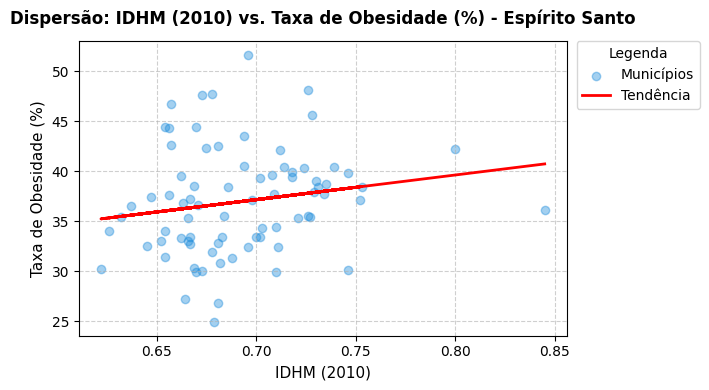

In [235]:
grafico_IDHM_Obesidade(df_consolidado_es, 'Espírito Santo')

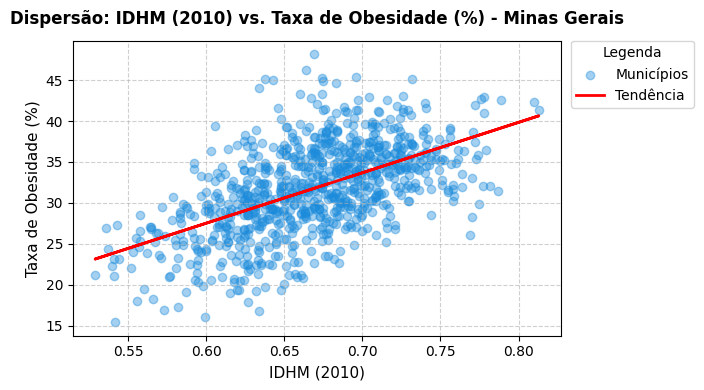

In [236]:
grafico_IDHM_Obesidade(df_consolidado_mg, 'Minas Gerais')

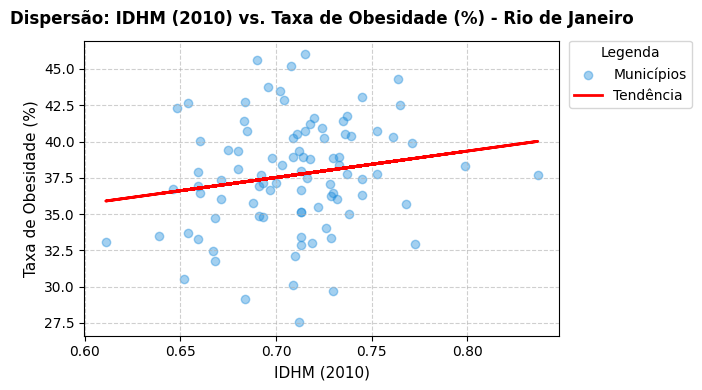

In [237]:
grafico_IDHM_Obesidade(df_consolidado_rj, 'Rio de Janeiro')

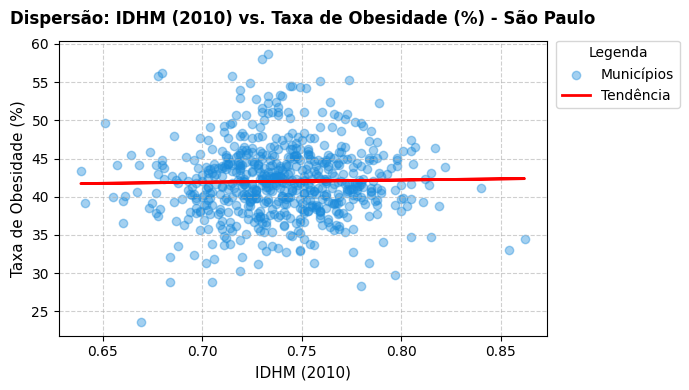

In [238]:
grafico_IDHM_Obesidade(df_consolidado_sp, 'São Paulo')

- **Verificação da relação dos Graus de Obesidade e do IDHM 2020 - 2025**

In [ ]:
grupo_grau_de_obesidade = df_mg_consolidado.groupby('faixa_idhm')[['Obesidade Grau I %', 'Obesidade Grau II %','Obesidade Grau III %']].mean().round(2)

grupo_grau_de_obesidade.style.format("{:.2f}").set_caption("Evolução Média dos Graus de Obesidade (%) por Faixa de IDHM (2020-2025)").set_table_styles([{'selector': 'caption', 'props': [('font-weight', 'bold'), ('font-size', '11pt')]}])

- Evolução anual **Obesidade Grau I** em relação as faixas de IDHM

In [ ]:
evolucao__anual_GrauI = df_mg_consolidado.groupby(['faixa_idhm', 'ano'])['Obesidade Grau I %'].mean().unstack()

evolucao__anual_GrauI.style.format("{:.2f}").set_caption("Evolução da Obesidade Grau I (%) por Faixa de IDHM (2020–2025)").set_table_styles([{'selector': 'caption','props':[('font-weight', 'bold'), ('font-size', '11pt')]}])

- Evolução anual **Obesidade Grau II** em relação as faixas de IDHM

In [ ]:
evolucao__anual_GrauII = df_mg_consolidado.groupby(['faixa_idhm', 'ano'])['Obesidade Grau II %'].mean().unstack()

evolucao__anual_GrauII.style.format("{:.2f}").set_caption("Evolução da Obesidade Grau II (%) por Faixa de IDHM (2020–2025)").set_table_styles([
    {'selector': 'caption','props':[('font-weight', 'bold'), ('font-size', '11pt')]}])

- Evolução anual **Obesidade Grau III** em relação as faixas de IDHM

In [ ]:
evolucao__anual_GrauIII = df_mg_consolidado.groupby(['faixa_idhm', 'ano'])['Obesidade Grau III %'].mean().unstack()

evolucao__anual_GrauIII.style.format("{:.2f}").set_caption("Evolução da Obesidade Grau III (%) por Faixa de IDHM (2020–2025)").set_table_styles([{'selector': 'caption','props':[('font-weight', 'bold'), ('font-size', '11pt')]}])

* Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN

In [ ]:
totais_por_faixa = df_mg_consolidado.groupby(['ano', 'faixa_idhm'])[['obesidade_total', 'Total']].sum()

totais_por_faixa['prevalencia %'] = (totais_por_faixa['obesidade_total'] / totais_por_faixa['Total'] * 100).round(2)

totais_por_faixa

In [ ]:
df_pivot = totais_por_faixa['prevalencia %'].unstack()

plt.figure(figsize=(9, 4))

faixas = ['Baixo', 'Médio', 'Alto', 'Muito Alto']

for faixa in faixas:
    if faixa in df_pivot.columns:
        plt.plot(
            df_pivot.index,
            df_pivot[faixa],
            marker='o',
            linewidth=2.5,
            label=f'IDHM {faixa}',
        )

        for ano in df_pivot.index:
            valor = df_pivot.loc[ano, faixa]
            plt.annotate(
                f'{valor:.2f}%',
                (ano, valor),
                textcoords='offset points',
                xytext=(0, 7),
                ha='center',
                fontsize=8.5,
                fontweight='bold',
            )

plt.title(
    'Prevalência agregada de obesidade entre os indivíduos avaliados no SISVAN',
    fontsize=11,
    fontweight='bold',
    pad=10,
)
plt.xlabel('Ano', fontsize=11)
plt.ylabel('Prevalência de Obesidade (%)', fontsize=11)

plt.ylim(18, 48)
plt.xticks(df_pivot.index)
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(
    title='Faixa IDHM',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0,
)

plt.tight_layout()
plt.show()

* **Nomes dos municípios em cada uma das faixas de IDHM**

In [ ]:
cidades_idhm_muito_alto = df_mg_consolidado[(df_mg_consolidado['faixa_idhm'] == 'Muito Alto') & (df_mg_consolidado ['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

cidades_idhm_muito_alto



In [ ]:
cidades_idhm_baixo = df_mg_consolidado[(df_mg_consolidado['faixa_idhm'] == 'Baixo') & (df_mg_consolidado['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

'''print(cidades_idhm_baixo['municipio_norm'].tolist())

with pd.option_context('display.max_rows', None):
    display(cidades_idhm_baixo)'''

cidades_idhm_baixo

In [ ]:
cidades_idhm_medio = df_mg_consolidado[(df_mg_consolidado['faixa_idhm'] == 'Médio') & (df_mg_consolidado['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

'''print(cidades_idhm_medio['municipio_norm'].tolist())

with pd.option_context('display.max_rows', None):
    display(cidades_idhm_medio)'''

cidades_idhm_medio

In [ ]:
cidades_idhm_alto = df_mg_consolidado[(df_mg_consolidado['faixa_idhm'] == 'Alto') & (df_mg_consolidado['ano'] == 2020)][['municipio_norm', 'faixa_idhm', 'idhm_2010']]

'''print(cidades_idhm_alto['municipio_norm'].tolist())

with pd.option_context('display.max_rows', None):
    display(cidades_idhm_alto)'''

cidades_idhm_alto